<a href="https://colab.research.google.com/github/ArseniyFaryna/Intelligent_analisis_labs/blob/main/%D0%9B%D0%A06_%D0%B7%D0%B0%D0%B2%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F_%D1%81%D1%82%D1%83%D0%B4%D0%B5%D0%BD%D1%82%D1%83.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [7]:
STUDENT_NAME = 'Фариан Арсеній Петрович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 31    # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 1, файл lr6_варіант_01.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [8]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [9]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [10]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: цільова змінна - розірвав контракт чи ні

METRIC = 'F1'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: оскільки розірвань мало, тому точність оманлива оцінка, а F1 балансує між точністю і повнотою при фіксованому розмірі дзвінків

CV_SCHEME = 'стратифікована 5-кратна KFold, 3 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: стратифікація зберігає частку рідкісного класу в кожному фолді, шафл рівномірно розподіляє клієнтів, а повтори роблять оцінку F1 стабільнішою.

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [11]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.293

типи стовпців: {'object': 13, 'float64': 7, 'int64': 6}


In [12]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.
df = pd.read_csv(os.path.join('дані', DATA))

profile = pd.DataFrame({
    'тип': df.dtypes.astype(str),
    'унікальних': df.nunique(dropna=True),
    '% пропусків': (df.isna().mean() * 100).round(2),
    'приклад': df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})
profile.index.name = 'стовпець'
profile = profile.sort_values('% пропусків', ascending=False)

with pd.option_context('display.max_rows', None, 'display.max_colwidth', 40):
    display(profile)

print('рядків:', len(df), '| стовпців:', df.shape[1])

,тип,унікальних,% пропусків,приклад
стовпець,,,,
код_причини_закриття,object,5,70.67,ПЕР-04
сума_повернення_депозиту,float64,351,70.67,121.49
середній_час_відповіді_хв,float64,264,33.75,25.7
трафік_ГБ,object,974,5.00,101.3
щомісячний_платіж,object,1129,4.00,270.14
аварій_на_ділянці_за_квартал,float64,6,3.00,0.0
стать,object,6,0.00,ч
місто,object,6,0.00,Стрий
id_клієнта,object,1200,0.00,K10000


рядків: 1200 | стовпців: 26


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [13]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----
for col in ['трафік_ГБ', 'щомісячний_платіж']:
    s = df[col]
    num = pd.to_numeric(s, errors='coerce')
    bad = s[s.notna() & num.isna()]
    print(f'{col}: нечислових значень {len(bad)} з {s.notna().sum()}')
    print(bad.value_counts().head(5))
    print('---')

bad_excel = df.loc[df['трафік_ГБ'].astype(str).str.startswith('1900'),
                   ['id_клієнта', 'трафік_ГБ']]
print(bad_excel)
print('рядків із датою замість числа:', len(bad_excel))

print(df['трафік_ГБ'].dropna().sample(5, random_state=SEED).tolist())

for c in ['код_причини_закриття', 'сума_повернення_депозиту']:
    miss = df[c].isna()
    print(f'{c}:')
    print(f'  пропусків: {miss.mean():.2%}')
    print(f'  відтік серед пропусків: {df.loc[miss, "відтік"].mean():.2%}')
    print(f'  відтік серед заповнених: {df.loc[~miss, "відтік"].mean():.2%}')
    print()

трафік_ГБ: нечислових значень 2 з 1140
трафік_ГБ
1900-01-25 00:00:00    1
1900-01-15 00:00:00    1
Name: count, dtype: int64
---
щомісячний_платіж: нечислових значень 27 з 1152
щомісячний_платіж
393.67 грн    1
426.37 грн    1
331.12 грн    1
369.93 грн    1
341.36 грн    1
Name: count, dtype: int64
---
стовпець id_клієнта            трафік_ГБ
444          K10444  1900-01-25 00:00:00
910          K10910  1900-01-15 00:00:00
рядків із датою замість числа: 2
['83.2', '331.0', '167.3', '250.1', '382.9']
код_причини_закриття:
  пропусків: 70.67%
  відтік серед пропусків: 0.00%
  відтік серед заповнених: 100.00%

сума_повернення_депозиту:
  пропусків: 70.67%
  відтік серед пропусків: 0.00%
  відтік серед заповнених: 100.00%



In [14]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'    # назва стовпця
PROBLEM_MNAR           = 'код_причини_закриття'    # назва стовпця
MNAR_MEANING           = 'пропуск означає, що значення не існувало в момент, коли був зроблений запис, або що сам факт відсутності залежить від того, що ми прогнозуємо, тож пропуск сам несе інформацію'    # що означає сам факт пропуску, одним реченням

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [15]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        # ----- ВАШ КОД -----
        # 1) None / NaN            -> np.nan
        if v is None or pd.isna(v):
            return np.nan
        # 2) datetime / Timestamp  -> np.nan   (це брак, а не дані)
        if isinstance(v, (datetime.datetime, datetime.date, pd.Timestamp)):
            return np.nan
        # 3) число                 -> float
        if isinstance(v, (int, float, np.integer, np.floating)):
            return float(v)
        # 4) текст                 -> перше число в ньому, інакше np.nan
        m = re.search(r'-?\d+(?:[.,]\d+)?', str(v))
        if not m:
            return np.nan
        return float(m.group().replace(',', '.'))
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [16]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується
NUM_PATTERN = r'^\s*-?\d+(?:[.,]\d+)?\s*(?:\D.*)?$'
DATE_STR = r'^\d{4}-\d{2}-\d{2}'
DATE_START = pd.Timestamp('2000-01-01')

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]

        if c == 'дата_підключення':
            dt = pd.to_datetime(s.astype(str).str.strip(), format='%Y-%m-%d', errors='coerce')
            X[c + '_день'] = (dt - DATE_START).dt.days.astype(float)
            log.append({'стовпець': c, 'рішення': 'число (дні від 2000-01-01)',
                        'пояснення': "дата -> порядковий номер дня, інакше модель її не з'їсть"})
            continue

        if pd.api.types.is_numeric_dtype(s):
            X[c] = s.astype(float)
            log.append({'стовпець': c, 'рішення': 'число', 'пояснення': 'вже числова'})
            continue

        s_str = s.astype(str).str.strip()
        is_date = s_str.str.match(DATE_STR) & s.notna()
        rest = s[~is_date & s.notna()].astype(str).str.strip()
        share_num = rest.str.match(NUM_PATTERN).mean() if len(rest) else 0.0

        if share_num > 0.8:
            X[c] = to_number(s.where(~is_date))
            log.append({'стовпець': c, 'рішення': 'число',
                        'пояснення': f'{share_num:.0%} значень починаються з числа, '
                                     f'дати у тексті ({is_date.sum()}) -> NaN'})
        else:
            X[c] = s_str.str.lower().where(s.notna()).astype('category')
            log.append({'стовпець': c, 'рішення': 'категорія',
                        'пояснення': f'числом починаються лише {share_num:.0%} значень'})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 9


,стовпець,рішення,пояснення
0,вік,число,вже числова
1,стать,категорія,числом починаються лише 0% значень
2,місто,категорія,числом починаються лише 0% значень
3,філія,категорія,числом починаються лише 0% значень
4,тариф,категорія,числом починаються лише 0% значень
5,тип_підключення,категорія,числом починаються лише 0% значень
6,спосіб_оплати,категорія,числом починаються лише 0% значень
7,автоплатіж,категорія,числом починаються лише 0% значень
8,кількість_послуг,число,вже числова
9,місяців_обслуговування,число,вже числова


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [17]:
def make_pipe(X, clf):
    # ----- ВАШ КОД -----
    num_cols = X.select_dtypes(include='number').columns.tolist()
    cat_cols = [c for c in X.columns if c not in num_cols]


    num_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median', add_indicator=True)),
        ('scale', StandardScaler()),
    ])

    cat_pipe = Pipeline([
        ('to_obj', FunctionTransformer(lambda d: d.astype(object), feature_names_out='one-to-one')),
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ])

    prep = ColumnTransformer([
        ('num', num_pipe, num_cols),
        ('cat', cat_pipe, cat_cols),
    ], remainder='drop')

    return Pipeline([('prep', prep), ('clf', clf)])

def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 1.000


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [18]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 1.000 ± 0.000
час      : 1.2 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [19]:
FIRST_REACTION = 'AUC = 1.0 означає ідеальне розділення клієнтів, які пішли, і тих, що лишилися, чого не буває там, де рішення залежить від багатьох непомічених таблицею причин'
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC = 1.0 означає ідеальне розділення клієнтів, які пішли, і тих, що лишилися, чого не буває там, де рішення залежить від багатьох непомічених таблицею причин


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [20]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        # ----- ВАШ КОД -----
        filled = d[c].notna()
        n_fill, n_miss = int(filled.sum()), int((~filled).sum())

        # підказка: показник = roc_auc_score(y, d[c].notna().astype(int)),
        churn_fill = y[filled].mean() if n_fill else np.nan
        churn_miss = y[~filled].mean() if n_miss else np.nan
        # але рахувати його можна лише якщо обидві групи більші за min_group
        if n_fill > min_group and n_miss > min_group:
            auc = roc_auc_score(y, filled.astype(int))
            score = max(auc, 1 - auc)     # напрям неважливий: важить сила зв'язку
        else:
            score = np.nan

        rows.append({'ознака': c, 'заповнено': n_fill,
                     'частка_відтоку_де_заповнено': churn_fill,
                     'частка_відтоку_де_пропуск': churn_miss,
                     'показник': score})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,сума_повернення_депозиту,352,1.000000,0.000000,1.000000
23,код_причини_закриття,352,1.000000,0.000000,1.000000
17,середній_час_відповіді_хв,795,0.324528,0.232099,0.549850
16,аварій_на_ділянці_за_квартал,1164,0.288660,0.444444,0.510935
14,трафік_ГБ,1140,0.289474,0.366667,0.508844
12,щомісячний_платіж,1152,0.291667,0.333333,0.503859
0,id_клієнта,1200,0.293333,NaN,NaN
1,вік,1200,0.293333,NaN,NaN
2,стать,1200,0.293333,NaN,NaN
3,місто,1200,0.293333,NaN,NaN


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [21]:
TARGET_LEAK = [
    # 'назва_стовпця',   # чому його немає в момент прогнозу
    'сума_повернення_депозиту',   # депозит повертають лише після розірвання договору, тож у клієнта, що ще користується послугою, цієї суми не існує
    'код_причини_закриття',       # причину закриття фіксують у момент закриття договору, а в момент звернення договір ще чинний
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['сума_повернення_депозиту', 'код_причини_закриття']


In [22]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.912 ± 0.017


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [23]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'код_тарифного_плану', 'індекс_лояльності_CRM', 'дата_підключення_день', 'кількість_дзвінків_утримання']


In [24]:
HUMAN_LEAK = [
    # 'назва_стовпця',   # ким і КОЛИ заповнюється це поле
    'кількість_дзвінків_утримання', # її записує відділ утримання вже після того, як клієнт виявив намір піти, а на момент звернення таких дзвінків ще не було
]

HUMAN_LEAK_WHY = "детектор перевіряє лише факт заповненості, а ця колонка заповнена в усіх рядках, тому формально вона безпечна, і лише зміст поля показує, що воно з'являється після події"      # чому детектор із 5.1 його не спіймав

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.833 ± 0.035


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,частка_відтоку,клієнтів
філія,,
Ф-02 Захід,0.462,212
Ф-01 Центр,0.414,198
Ф-04 Південь,0.239,176
Ф-06 Приміська,0.231,216
Ф-05 Північ,0.230,200
Ф-03 Схід,0.172,198


,частка_відтоку,клієнтів
дата_підключення,,
2023Q1,0.250,128
2023Q2,0.315,146
2023Q3,0.309,162
2023Q4,0.344,157
2024Q1,0.297,155
2024Q2,0.275,167
2024Q3,0.265,136
2024Q4,0.282,149


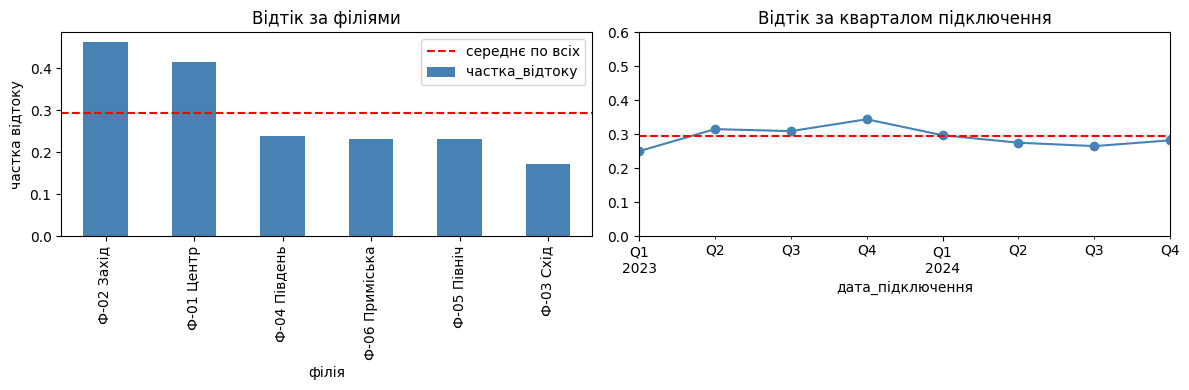

In [25]:
# ----- ВАШ КОД -----
# 1) частка відтоку за кожною філією (і скільки клієнтів у кожній);
by_branch = (raw.groupby('філія')[TARGET]
                .agg(частка_відтоку='mean', клієнтів='size')
                .round(3)
                .sort_values('частка_відтоку', ascending=False))
display(by_branch)
# 2) частка відтоку по кварталах дати підключення — таблицею або графіком.
quarter = pd.to_datetime(raw['дата_підключення'], format='%Y-%m-%d').dt.to_period('Q')
by_quarter = (raw.groupby(quarter)[TARGET]
                 .agg(частка_відтоку='mean', клієнтів='size')
                 .round(3))
display(by_quarter)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
by_branch['частка_відтоку'].plot.bar(ax=ax[0], color='steelblue')
ax[0].axhline(raw[TARGET].mean(), color='red', ls='--', label='середнє по всіх')
ax[0].set_title('Відтік за філіями'); ax[0].set_ylabel('частка відтоку'); ax[0].legend()
by_quarter['частка_відтоку'].plot(ax=ax[1], marker='o', color='steelblue')
ax[1].axhline(raw[TARGET].mean(), color='red', ls='--')
ax[1].set_title('Відтік за кварталом підключення'); ax[1].set_ylim(0, 0.6)
plt.tight_layout()
plt.show()
# Шукайте СХОДИНКУ, а не плавну зміну.

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [26]:
SUSPECT = 'філія'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

# ----- ВАШ КОД: побудуйте бінарну змінну source -----
# для 'філія'          : 1 для філій із різко іншою часткою відтоку
SUSPECT_BRANCHES = ['Ф-01 Центр', 'Ф-02 Захід']
source = raw['філія'].isin(SUSPECT_BRANCHES).astype(int)
print('частка клієнтів із підозрюваних філій: %.3f' % source.mean())

# для 'дата_підключення': 1 для клієнтів, підключених після дати-зламу

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

частка клієнтів із підозрюваних філій: 0.342
ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.705
ті самі ознаки передбачають ВІДТІК  : AUC 0.796 ± 0.038


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [27]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,1.000
2. мінус цільовий витік,22,0.912
3. мінус оцінки людини,21,0.833
4. мінус артефакт збору,20,0.796


чесне число: 0.796 ± 0.038


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [28]:
DECISION_ARTEFACT = 'викинути'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = 'за чесними ознаками філію-джерело вгадує AUC 0.705, тож клієнти різних філій відрізняються способом запису чи складом, і модель, навчена з філією, вивчала б особливості Центру й Заходу, а не причини відтоку'
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — за чесними ознаками філію-джерело вгадує AUC 0.705, тож клієнти різних філій відрізняються способом запису чи складом, і модель, навчена з філією, вивчала б особливості Центру й Заходу, а не причини відтоку


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [29]:
MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),   # ----- ВАШ КОД -----
    'випадковий ліс':       RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1),   # ----- ВАШ КОД -----
    'гістограмний бустинг': HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, max_depth=3, random_state=SEED)   # ----- ВАШ КОД -----
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.796,0.038,1.3
одне дерево,0.729,0.034,0.8
випадковий ліс,0.801,0.036,15.5
гістограмний бустинг,0.822,0.032,4.9


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [30]:
from scipy import stats

def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    # ----- ВАШ КОД -----
    d = np.asarray(b) - np.asarray(a)
    n = len(d)
    half = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
    return d.mean(), half


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0051 ± 0.0099   у межах шуму
гістограмний бустинг   проти логістичної: +0.0261 ± 0.0072   значуще


In [31]:
CHOSEN_MODEL = 'гістограмний бустинг'     # назва з MODELS
CHOSEN_WHY = 'єдина модель, яка значуще краща за логістичну регресію (приріст AUC +0.028 ± 0.007) за парним порівнянням, AUC 0.823 проти 0.796, тоді як ліс (+0.005 ± 0.010) ціна мала й прийнятна, а ліс при нульовому виграші втричі повільніший; інтерпретовність: гірша, ніж у логістичної регресії, але дерева пояснюються через SHAP, тож пояснення для менеджера все одно можна отримати.'      # за якими з чотирьох критеріїв і чому саме так
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: гістограмний бустинг — єдина модель, яка значуще краща за логістичну регресію (приріст AUC +0.028 ± 0.007) за парним порівнянням, AUC 0.823 проти 0.796, тоді як ліс (+0.005 ± 0.010) ціна мала й прийнятна, а ліс при нульовому виграші втричі повільніший; інтерпретовність: гірша, ніж у логістичної регресії, але дерева пояснюються через SHAP, тож пояснення для менеджера все одно можна отримати.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [32]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # ----- ВАШ КОД: щонайменше три ознаки, кожна з коментарем-гіпотезою -----
    F['ціна_за_мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт'].replace(0, np.nan)

    # гіпотеза: важлива не кількість звернень, а їхня частота; п'ять звернень за пів року
    # тривожніше, ніж п'ять за п'ять років
    F['звернень_на_місяць'] = (F['кількість_звернень_у_підтримку']
                               / (F['місяців_обслуговування'] + 1))

    # гіпотеза: клієнт, який майже не використовує оплачений трафік, не бачить цінності
    # в послузі, тому трафік на гривню краще за сам трафік показує віддачу від платежу
    F['трафік_на_гривню'] = F['трафік_ГБ'] / F['щомісячний_платіж'].replace(0, np.nan)

    # гіпотеза: наявність знижки як факт відрізняється від її розміру; знижка 0 і 10 %
    # можуть діяти якісно по-різному
    F['є_знижка'] = (F['знижка_відсоток'] > 0).astype(float)

    # гіпотеза: перший рік обслуговування найризикованіший, бо клієнт ще не звик
    # до провайдера і легко переходить до конкурента
    F['новий_клієнт'] = (F['місяців_обслуговування'] <= 12).astype(float)
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 25


In [33]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.796 ± 0.039
приріст проти базового набору: +0.0003 ± 0.0029   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [34]:
FEATURES_VS_MODEL = 'Складніша модель дала більше. Гістограмний бустинг покращив AUC на +0.028 ± 0.007 (значуще, інтервал не накриває нуль) ціною приблизно 2 секунд додаткового часу (2.6 с проти 0.6 с на 20 навчань), а п\'ять нових ознак дали лише +0.0003 ± 0.0029, тобто нуль у межах шуму, і майже нічого не коштували в секундах; отже, у цих даних бракувало гнучкості моделі, а не ознак, які можна було б порахувати з наявних колонок.'
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Складніша модель дала більше. Гістограмний бустинг покращив AUC на +0.028 ± 0.007 (значуще, інтервал не накриває нуль) ціною приблизно 2 секунд додаткового часу (2.6 с проти 0.6 с на 20 навчань), а п'ять нових ознак дали лише +0.0003 ± 0.0029, тобто нуль у межах шуму, і майже нічого не коштували в секундах; отже, у цих даних бракувало гнучкості моделі, а не ознак, які можна було б порахувати з наявних колонок.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [35]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.811
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

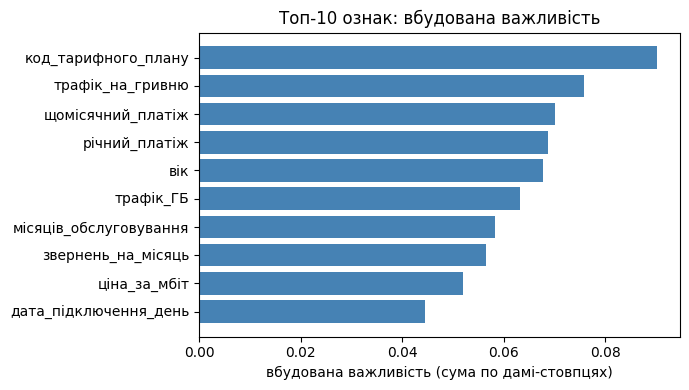

,0
код_тарифного_плану,0.090
трафік_на_гривню,0.076
щомісячний_платіж,0.070
річний_платіж,0.069
вік,0.068
трафік_ГБ,0.063
місяців_обслуговування,0.058
звернень_на_місяць,0.056
ціна_за_мбіт,0.052
дата_підключення_день,0.045


In [36]:
# ----- ВАШ КОД -----
# 1) дістаньте імена після перетворення: model.named_steps['prep'].get_feature_names_out()
names = model.named_steps['prep'].get_feature_names_out()
imp = pd.Series(model.named_steps['clf'].feature_importances_, index=names)

# 2) підсумуйте важливості дамі-стовпців до вихідних ознак
orig = list(FINAL_X.columns)

def to_orig(n):
    n = n.split('__', 1)[1]
    if n.startswith('missingindicator_'):
        n = n[len('missingindicator_'):]
    cand = [c for c in orig if n == c or n.startswith(c + '_')]
    return max(cand, key=len)

gini_imp = imp.groupby(to_orig).sum().sort_values(ascending=False)
assert abs(gini_imp.sum() - 1) < 1e-6 and len(gini_imp) == len(orig)

# 3) побудуйте горизонтальну стовпчикову діаграму топ-10
top = gini_imp.head(10)[::-1]
plt.figure(figsize=(7, 4))
plt.barh(top.index, top.values, color='steelblue')
plt.xlabel('вбудована важливість (сума по дамі-стовпцях)')
plt.title('Топ-10 ознак: вбудована важливість')
plt.tight_layout(); plt.show()
display(gini_imp.head(10).round(3))

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [37]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.053452
трафік_на_гривню,0.027592
місяців_обслуговування,0.025617
річний_платіж,0.013761
трафік_ГБ,0.012931
звернень_на_місяць,0.012667
аварій_на_ділянці_за_квартал,0.008299
швидкість_тарифу_Мбіт,0.006854
щомісячний_платіж,0.004279
дата_підключення_день,0.003792


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [38]:
# ----- ВАШ КОД: таблиця «ознака | вбудована | перестановочна», відсортована за вбудованою -----
cmp = pd.DataFrame({'вбудована': gini_imp,
                    'перестановочна': perm_imp}).sort_values('вбудована', ascending=False)
cmp['ранг вбудованої'] = range(1, len(cmp) + 1)
cmp['ранг перестановочної'] = cmp['перестановочна'].rank(ascending=False).astype(int)
display(cmp.head(10).round(4))

,вбудована,перестановочна,ранг вбудованої,ранг перестановочної
код_тарифного_плану,0.0902,0.0010,1,17
трафік_на_гривню,0.0758,0.0276,2,2
щомісячний_платіж,0.0701,0.0043,3,9
річний_платіж,0.0687,0.0138,4,4
вік,0.0678,0.0535,5,1
трафік_ГБ,0.0631,0.0129,6,5
місяців_обслуговування,0.0582,0.0256,7,3
звернень_на_місяць,0.0564,0.0127,8,6
ціна_за_мбіт,0.0520,0.0020,9,13
дата_підключення_день,0.0446,0.0038,10,10


In [39]:
FAKE_IMPORTANT = 'код_тарифного_плану'        # назва ознаки
FAKE_IMPORTANT_WHY = 'ознака має 40 різних значень, тож дерево отримує багато можливих порогів і майже завжди знаходить розбиття, яке трохи зменшує неоднорідність навіть без зв\'язку з ціллю, через що вбудована важливість її переоцінює (перше місце, 0.090), а перестановка на відкладеній вибірці показує майже нуль (0.001)'    # чому вбудована важливість її переоцінює
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: код_тарифного_плану


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [40]:
# ----- ВАШ КОД: кореляційна матриця числових ознак, знайдіть пару з |r| > 0.97 -----
corr = FINAL_X.select_dtypes('number').corr().abs()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns)
         for b in corr.columns[i + 1:] if corr.loc[a, b] > 0.97]
print('пари з |r| > 0.97:', [(a, b, round(r, 4)) for a, b, r in pairs])
a, b, _ = pairs[0]

print('\nповна модель:')
print('  %-20s %.4f' % (a, perm_imp[a]))
print('  %-20s %.4f' % (b, perm_imp[b]))
print('  сума                 %.4f' % (perm_imp[a] + perm_imp[b]))

def refit_without(drop):
    cols = [c for c in FINAL_X.columns if c != drop]
    m = make_pipe(FINAL_X[cols], RandomForestClassifier(n_estimators=300, random_state=SEED,
                                                        n_jobs=-1)).fit(Xtr[cols], ytr)
    p = permutation_importance(m, Xte[cols], yte, n_repeats=10,
                               random_state=SEED, scoring='roc_auc')
    return pd.Series(p.importances_mean, index=cols), roc_auc_score(yte, m.predict_proba(Xte[cols])[:, 1])

imp_wo, auc_wo = refit_without(a)
print('\nбез %s:' % a)
print('  %-20s %.4f   (AUC на відкладеній частині %.3f)' % (b, imp_wo[b], auc_wo))

пари з |r| > 0.97: [('щомісячний_платіж', 'річний_платіж', np.float64(0.9991))]

повна модель:
  щомісячний_платіж    0.0043
  річний_платіж        0.0138
  сума                 0.0180

без щомісячний_платіж:
  річний_платіж        0.0258   (AUC на відкладеній частині 0.807)


In [41]:
DUP_PAIR = ['щомісячний_платіж', 'річний_платіж']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# ----- ВАШ КОД: приберіть DUP_PAIR[1], навчіть заново, порахуйте перестановочну -----
# і виведіть важливість DUP_PAIR[0] без пари
cols = [c for c in FINAL_X.columns if c != DUP_PAIR[1]]
model_wo = make_pipe(FINAL_X[cols], RandomForestClassifier(n_estimators=300, random_state=SEED,
                                                           n_jobs=-1)).fit(Xtr[cols], ytr)
perm_wo = permutation_importance(model_wo, Xte[cols], yte, n_repeats=10,
                                 random_state=SEED, scoring='roc_auc')
imp_wo = pd.Series(perm_wo.importances_mean, index=cols)

print('\nбез %s:' % DUP_PAIR[1])
print('   %-28s %+.4f' % (DUP_PAIR[0], imp_wo[DUP_PAIR[0]]))

у повній моделі:
   щомісячний_платіж            +0.0043
   річний_платіж                +0.0138

без річний_платіж:
   щомісячний_платіж            +0.0224


In [42]:
DUP_EXPLANATION = 'Щомісячний_платіж і річний_платіж вимірюють те саме в різних одиницях (r = 0.999), тому в повній моделі, коли перестановка псує одну з них, модель бере ту саму інформацію з другої, і важливість ділиться між ними й виходить малою. Після вилучення річний_платіж уся ця інформація лишається тільки в щомісячний_платіж, і його важливість зростає до 0.022, хоча сама ознака не змінилася, тож низька перестановочна важливість корельованої ознаки не означає, що вона марна.'
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

Щомісячний_платіж і річний_платіж вимірюють те саме в різних одиницях (r = 0.999), тому в повній моделі, коли перестановка псує одну з них, модель бере ту саму інформацію з другої, і важливість ділиться між ними й виходить малою. Після вилучення річний_платіж уся ця інформація лишається тільки в щомісячний_платіж, і його важливість зростає до 0.022, хоча сама ознака не змінилася, тож низька перестановочна важливість корельованої ознаки не означає, що вона марна.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

PDP для: ['вік', 'трафік_на_гривню', 'місяців_обслуговування']


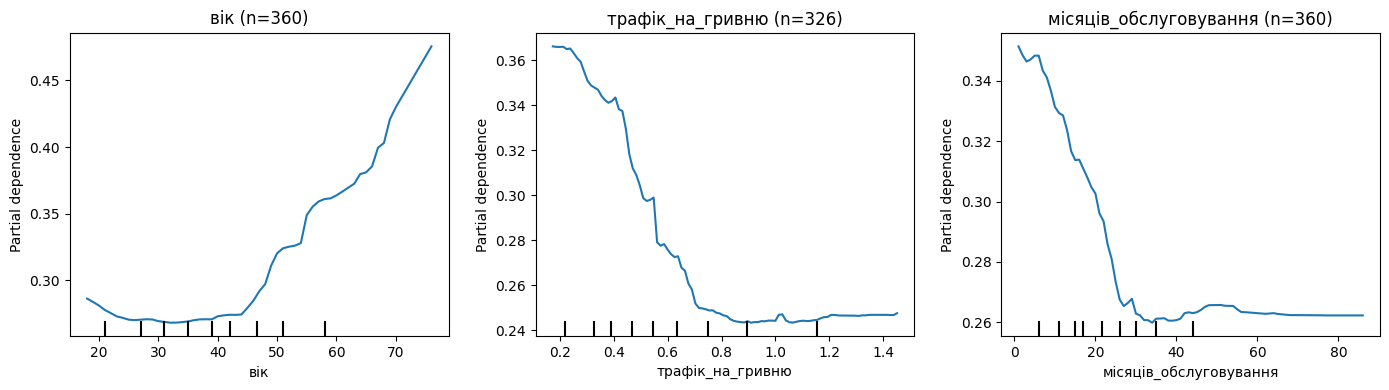

In [43]:
from sklearn.inspection import PartialDependenceDisplay

# ----- ВАШ КОД -----
# PartialDependenceDisplay.from_estimator(model, Xte, features=[...], kind='average')
# Увага: ознака з пропусками дасть порожню сітку — беріть ознаки без NaN
# або будуйте PDP на підвибірці, де ця ознака заповнена.
top3 = [c for c in perm_imp.index if pd.api.types.is_numeric_dtype(FINAL_X[c])][:3]
print('PDP для:', top3)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, f in zip(axes, top3):
    d = Xte[Xte[f].notna()]            # ознака з NaN дала б порожню сітку
    PartialDependenceDisplay.from_estimator(model, d, [f], kind='average', ax=ax)
    ax.set_title('%s (n=%d)' % (f, len(d)))
axes[0].set_ylabel('середній прогноз ризику відтоку')
plt.tight_layout(); plt.show()

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

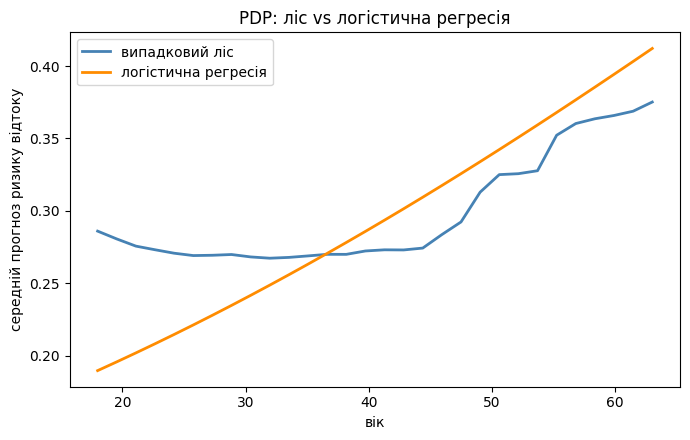

In [44]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

# ----- ВАШ КОД: один рисунок, дві криві — ліс і логістична регресія -----
logreg_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, m, color in [('випадковий ліс', model, 'steelblue'),
                       ('логістична регресія', logreg_model, 'darkorange')]:
    r = partial_dependence(m, FINAL_X, [NONLINEAR_FEATURE], kind='average', grid_resolution=30)
    ax.plot(r['grid_values'][0], r['average'][0], label=name, color=color, lw=2)
ax.set_xlabel(NONLINEAR_FEATURE)
ax.set_ylabel('середній прогноз ризику відтоку')
ax.set_title('PDP: ліс vs логістична регресія')
ax.legend(); plt.tight_layout(); plt.show()

In [45]:
NONLINEAR_MEANING = 'Ризик відтоку найнижчий у клієнтів середнього віку (приблизно 30-45 років), а в наймолодших (до 25 років) і особливо у старших за 50 він вищий: молоді легше змінюють провайдера і ще не прив\'язані до послуги, а старші клієнти частіше відмовляються від послуг або переїжджають, тому залежність U-подібна, а не лінійна'     # що означає ця форма змістовно, мовою предметної області
NONLINEAR_FIX = 'Додати ознаку «відстань від найнижчої точки», наприклад ((вік - 35) / 10) ** 2, тобто квадрат відхилення від віку з мінімальним ризиком (або розбити вік на групи до 25, 25-45, 45-55, понад 55), щоб лінійна модель могла дати високі коефіцієнти на обох краях'         # яку ознаку треба сконструювати, щоб лінійна модель це побачила
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

Ризик відтоку найнижчий у клієнтів середнього віку (приблизно 30-45 років), а в наймолодших (до 25 років) і особливо у старших за 50 він вищий: молоді легше змінюють провайдера і ще не прив'язані до послуги, а старші клієнти частіше відмовляються від послуг або переїжджають, тому залежність U-подібна, а не лінійна
Додати ознаку «відстань від найнижчої точки», наприклад ((вік - 35) / 10) ** 2, тобто квадрат відхилення від віку з мінімальним ризиком (або розбити вік на групи до 25, 25-45, 45-55, понад 55), щоб лінійна модель могла дати високі коефіцієнти на обох краях


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [46]:
# ----- ВАШ КОД -----
# 1) зчитайте з графіка значення, при якому ризик мінімальний;
r = partial_dependence(model, FINAL_X, ['вік'], kind='average', grid_resolution=50)
age_min = float(r['grid_values'][0][np.argmin(r['average'][0])])
print('мінімум PDP лісу при віці %.1f' % age_min)

# 2) додайте ознаку «квадрат відхилення від цього значення»;
X6 = FINAL_X.copy()
X6['вік_відхилення_кв'] = (X6['вік'] - age_min) ** 2

# 3) парне порівняння логістичної регресії з нею і без неї.
base_lr = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
with_lr = cross_val_score(make_pipe(X6, logreg()), X6, y, cv=cv, scoring='roc_auc')
m, h = paired(base_lr, with_lr)
print('логістична регресія без ознаки: AUC %.3f ± %.3f' % (base_lr.mean(), base_lr.std()))
print('логістична регресія з ознакою : AUC %.3f ± %.3f' % (with_lr.mean(), with_lr.std()))
print('приріст: %+.4f ± %.4f   %s' % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

мінімум PDP лісу при віці 31.8
логістична регресія без ознаки: AUC 0.796 ± 0.039
логістична регресія з ознакою : AUC 0.811 ± 0.035
приріст: +0.0155 ± 0.0045   значуще


In [47]:
QUAD_GAIN = m     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0155


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

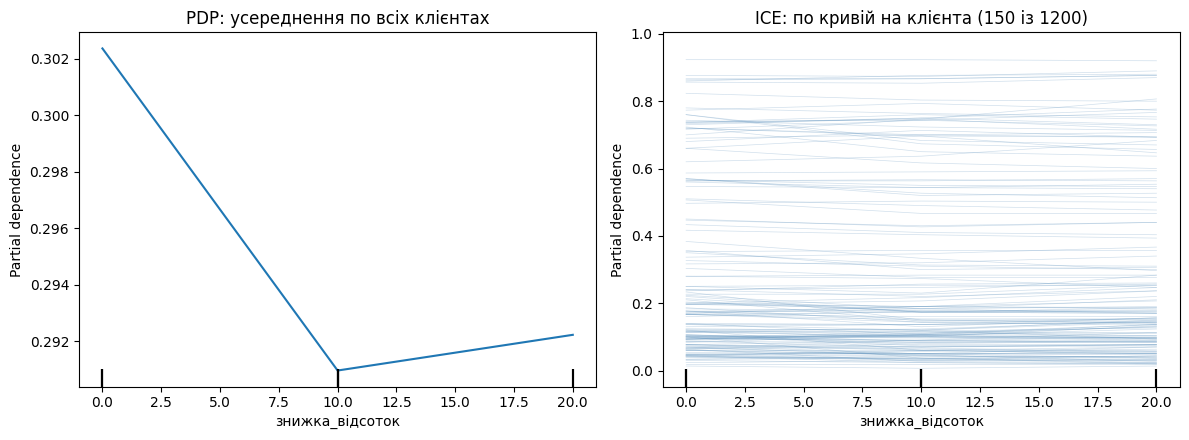

сітка знижки: [ 0. 10. 20.]  PDP: [0.302 0.291 0.292]
ризик росте у 31% клієнтів, спадає у 54%
зсув ризику від -0.137 до +0.107


In [48]:
# ----- ВАШ КОД: пункт 1 і 2, PDP та ICE для 'знижка_відсоток' -----
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'],
                                        kind='average', ax=ax[0])
ax[0].set_title('PDP: усереднення по всіх клієнтах')

PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'],
                                        kind='individual', subsample=150,
                                        random_state=SEED, ax=ax[1],
                                        ice_lines_kw={'alpha': 0.25, 'color': 'steelblue'})
ax[1].set_title('ICE: по кривій на клієнта (150 із 1200)')
plt.tight_layout(); plt.show()

r = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='both', grid_resolution=10)
delta = r['individual'][0][:, -1] - r['individual'][0][:, 0]   # зміна ризику: з макс. знижкою мінус без
print('сітка знижки:', r['grid_values'][0], ' PDP:', r['average'][0].round(3))
print('ризик росте у %.0f%% клієнтів, спадає у %.0f%%' % (100 * (delta > 0.005).mean(),
                                                         100 * (delta < -0.005).mean()))
print('зсув ризику від %+.3f до %+.3f' % (delta.min(), delta.max()))

стаж до 24 місяців     n=689  PDP: [0.355 0.354 0.358]
стаж понад 24 місяці   n=511  PDP: [0.231 0.205 0.203]


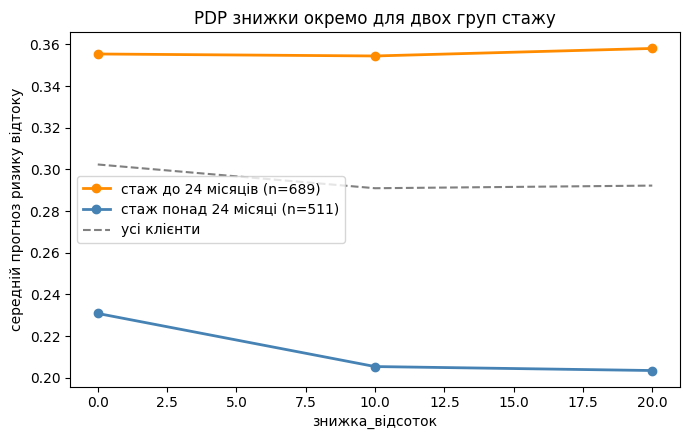

In [49]:
# ----- ВАШ КОД: пункт 3, дві криві на одному рисунку -----
# підказка: partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
groups = [('стаж до 24 місяців', FINAL_X['місяців_обслуговування'] <= 24, 'darkorange'),
          ('стаж понад 24 місяці', FINAL_X['місяців_обслуговування'] > 24, 'steelblue')]

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, mask, color in groups:
    r = partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
    ax.plot(r['grid_values'][0], r['average'][0], marker='o', lw=2, color=color,
            label='%s (n=%d)' % (name, mask.sum()))
    print('%-22s n=%d  PDP: %s' % (name, mask.sum(), r['average'][0].round(3)))

r_all = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='average')
ax.plot(r_all['grid_values'][0], r_all['average'][0], ls='--', color='gray', label='усі клієнти')

ax.set_xlabel('знижка_відсоток')
ax.set_ylabel('середній прогноз ризику відтоку')
ax.set_title('PDP знижки окремо для двох груп стажу')
ax.legend(); plt.tight_layout(); plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [50]:
# ----- ВАШ КОД: зведена таблиця «знижка x група стажу» -> частка відтоку і розмір групи -----
tenure_group = np.where(raw['місяців_обслуговування'] <= 24, 'стаж ≤ 24', 'стаж > 24')
tab = (raw.assign(група=tenure_group)
          .pivot_table(index='знижка_відсоток', columns='група',
                       values=TARGET, aggfunc=['mean', 'size']))
tab.columns = ['частка відтоку, %s' % g if f == 'mean' else 'клієнтів, %s' % g
               for f, g in tab.columns]
display(tab.round(3))

,"частка відтоку, стаж > 24","частка відтоку, стаж ≤ 24","клієнтів, стаж > 24","клієнтів, стаж ≤ 24"
знижка_відсоток,,,,
0,0.286,0.315,210,257
10,0.110,0.369,163,233
20,0.080,0.482,138,199


In [51]:
INTERACTION_FOUND = 'Знижка діє по-різному залежно від стажу: у клієнтів зі стажем понад 24 місяці відтік падає зі зростанням знижки, а в клієнтів зі стажем до 24 місяців навпаки зростає, тому PDP по всій вибірці майже пласкій, бо протилежні ефекти взаємно погасилися; при цьому ліс відтворив падіння у стажистів лише частково і зовсім не відтворив зростання в новачків'     # опишіть, що робить знижка в кожній із двох груп
BUSINESS_ACTION = 'Пропонувати знижку насамперед клієнтам зі стажем понад два роки, де вона пов\'язана зі значно нижчим відтоком, а новачкам не роздавати її однаково всім на підставі цієї таблиці, бо в них більша знижка зустрічається разом із вищим відтоком; Перш ніж змінювати політику, перевірити це експериментом із контрольною групою, яка знижки не отримує'       # що з цього випливає для відділу утримання
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

Знижка діє по-різному залежно від стажу: у клієнтів зі стажем понад 24 місяці відтік падає зі зростанням знижки, а в клієнтів зі стажем до 24 місяців навпаки зростає, тому PDP по всій вибірці майже пласкій, бо протилежні ефекти взаємно погасилися; при цьому ліс відтворив падіння у стажистів лише частково і зовсім не відтворив зростання в новачків
Пропонувати знижку насамперед клієнтам зі стажем понад два роки, де вона пов'язана зі значно нижчим відтоком, а новачкам не роздавати її однаково всім на підставі цієї таблиці, бо в них більша знижка зустрічається разом із вищим відтоком; Перш ніж змінювати політику, перевірити це експериментом із контрольною групою, яка знижки не отримує


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [52]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 86)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

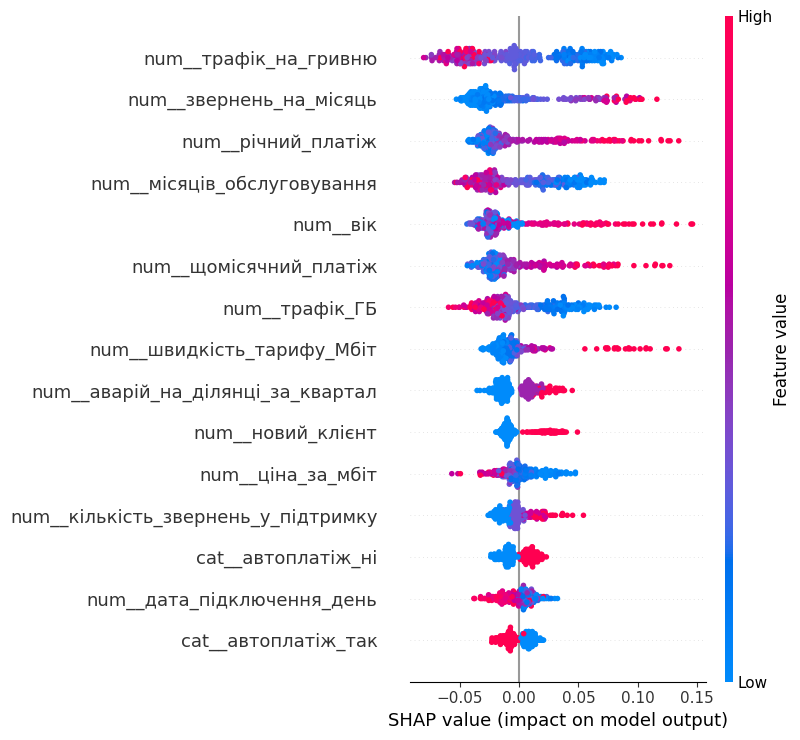

In [53]:
# ----- ВАШ КОД: shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names) -----
import scipy.sparse as sp
X_shap = Xte_t[:SAMPLE]
X_shap = X_shap.toarray() if sp.issparse(X_shap) else X_shap   # summary_plot хоче щільну матрицю

shap.summary_plot(sv1, X_shap, feature_names=feat_names, max_display=15)

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [54]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

# ----- ВАШ КОД: три найбільші за модулем внески для цього клієнта -----
contrib = pd.Series(sv1[idx], index=feat_names)
top3 = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(3)
print('базовий рівень: %.3f, сума внесків: %+.3f' % (float(np.ravel(expl.expected_value)[-1]), contrib.sum()))
print(top3.round(3))

orig_names = [n.split('__', 1)[1] for n in top3.index]
cmp_vals = pd.DataFrame({'клієнт': Xte.iloc[idx][orig_names],
                         'середнє по вибірці': Xte[orig_names].mean()})
display(cmp_vals.round(2))

ризик клієнта: 0.877
базовий рівень: 0.293, сума внесків: +0.583
num__річний_платіж            0.097
num__звернень_на_місяць       0.084
num__швидкість_тарифу_Мбіт    0.083
dtype: float64


,клієнт,середнє по вибірці
річний_платіж,5889.0,3837.77
звернень_на_місяць,0.333333,0.07
швидкість_тарифу_Мбіт,1000.0,298.89


In [55]:
EXPLANATION_FOR_MANAGER = 'Цей клієнт належить до найризикованіших: оцінка ймовірності розірвання 88 % проти приблизно 29 % у середньому по базі. Три головні причини. Він платить помітно більше за типового клієнта, часто звертається до підтримки, 4 рази за 11 місяців, приблизно вп\'ятеро частіше за типового клієнта'
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Цей клієнт належить до найризикованіших: оцінка ймовірності розірвання 88 % проти приблизно 29 % у середньому по базі. Три головні причини. Він платить помітно більше за типового клієнта, часто звертається до підтримки, 4 рази за 11 місяців, приблизно вп'ятеро частіше за типового клієнта


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [56]:
SHAP_NOT_CAUSAL_FEATURE = 'звернень_на_місяць'
SHAP_NOT_CAUSAL_WHY = 'Вона дає великий внесок, бо частота звернень до підтримки є симптомом проблеми, а не її причиною: клієнт звертається, коли в нього щось не працює або він незадоволений, і саме це незадоволення підвищує ймовірність відходу; значення Шеплі показують, що оцінка зростає разом із цією ознакою, але не що станеться з відтоком, якщо її змінити, а для такого висновку потрібен експеримент з контрольною групою'
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

звернень_на_місяць — Вона дає великий внесок, бо частота звернень до підтримки є симптомом проблеми, а не її причиною: клієнт звертається, коли в нього щось не працює або він незадоволений, і саме це незадоволення підвищує ймовірність відходу; значення Шеплі показують, що оцінка зростає разом із цією ознакою, але не що станеться з відтоком, якщо її змінити, а для такого висновку потрібен експеримент з контрольною групою


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [57]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",щомісячний_платіж + річний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",звернень_на_місяць,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [58]:
FIFTH_MISTAKE = 'середній_час_відповіді_хв: у 405 клієнтів значення немає, і всі вони не звертались до підтримки жодного разу, тож пропуск означає «не звертався», а не «час невідомий». Конвеєр заповнює його медіаною (~10 хв), тому клієнт, який ні разу не звертався, виглядає як клієнт із типовим часом відповіді; поруч конвеєр додає прапорець пропуску, і його внесок (0.008) порівнянний із внеском самого значення (0.007).'
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

середній_час_відповіді_хв: у 405 клієнтів значення немає, і всі вони не звертались до підтримки жодного разу, тож пропуск означає «не звертався», а не «час невідомий». Конвеєр заповнює його медіаною (~10 хв), тому клієнт, який ні разу не звертався, виглядає як клієнт із типовим часом відповіді; поруч конвеєр додає прапорець пропуску, і його внесок (0.008) порівнянний із внеском самого значення (0.007).


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [59]:
# ----- ВАШ КОД -----
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100
proba = model.predict_proba(Xte)[:, 1]
top_idx = np.argsort(-proba)[:TOP_N]

top_rate = yte.values[top_idx].mean()
base_rate = yte.mean()
lift = top_rate / base_rate

print('перевіркова частина: %d клієнтів, пішли %d (%.1f%%)' % (len(yte), yte.sum(), 100 * base_rate))
print('топ-%d: справді пішли %d (%.1f%%)' % (TOP_N, yte.values[top_idx].sum(), 100 * top_rate))
print('навмання очікувалось би ≈ %.0f' % (TOP_N * base_rate))
print('lift = %.2f' % lift)
TOP_N = 100

перевіркова частина: 360 клієнтів, пішли 106 (29.4%)
топ-100: справді пішли 61 (61.0%)
навмання очікувалось би ≈ 29
lift = 2.07


In [60]:
LIFT_MEANING = 'Якщо відділ утримання телефонуватиме 100 клієнтам зі списку, у ньому буде приблизно вдвічі більше таких, що справді збираються піти, тож кожен дзвінок у два рази частіше потрапляє в людину, яку ще можна втримати'    # що число lift означає для бізнесу, одним реченням
assert LIFT_MEANING
print(LIFT_MEANING)

Якщо відділ утримання телефонуватиме 100 клієнтам зі списку, у ньому буде приблизно вдвічі більше таких, що справді збираються піти, тож кожен дзвінок у два рази частіше потрапляє в людину, яку ще можна втримати


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [61]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_01.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [62]:
REPORT = '''
1. Обрано AUC, бо відділу потрібне ранжування клієнтів за ризиком, а не один поріг, і точність тут оманлива: модель «ніхто не піде» дає точність 70,7 %, хоча нікого не знаходить.
2. Викинуто id_клієнта, сума_повернення_депозиту і код_причини_закриття, кількість_дзвінків_утримання (записується відділом утримання вже після того, як клієнт виявив намір піти) і філія (артефакт збору); детектор із 5.1 не знайшов дзвінки, бо вони заповнені в усіх рядках (нулі замість пропусків), тож заповненість нічого не каже про клас.
3. Чесний AUC близько 0,80 з розкидом ±0,04 між згортками (логістична регресія 0,796 ± 0,039), тому різниця між двома моделями в 0,004 набагато менша за розкид і є шумом.
4. Так: у філіях Центр і Захід відтік 41–46 % проти 17–24 % в інших, а за чесними ознаками їхнього клієнта можна відрізнити з AUC 0,705, тож в іншій філії цій моделі можна довіряти лише обережно, і її якість треба перевірити на даних тієї філії.
5. Складніша модель дала більше: бустинг проти логістичної регресії +0,028 ± 0,007 (значуще) за 2,6 с проти 0,6 с на 20 навчань, а п'ять нових ознак лише +0,0003 ± 0,0029 (шум) практично без витрат часу.
6. Вбудована важливість помилково назвала важливою код_тарифного_плану (перше місце, а перестановочна майже нуль), бо ознака з 40 значеннями дає дереву багато можливих порогів, і воно майже завжди знаходить розбиття, що трохи зменшує неоднорідність навіть без зв'язку з ціллю.
7. Пара щомісячний_платіж і річний_платіж (r = 0,999) поділила важливість між собою (0,004 і 0,014), а після вилучення одного з них важливість другого зросла до 0,022–0,026, і це не вада методу, бо модель справді може замінити одну ознаку іншою, тож важливість треба оцінювати для групи.
8. Немонотонний вплив має вік (ризик мінімальний близько 32 років і зростає після 45), а логістична регресія без втручання цього не бачить і недооцінює молодих клієнтів (0,19 проти реальних 0,29), тоді як ознака «квадрат відхилення від 32» дала +0,0155 ± 0,0045.
9. PDP для знижка_відсоток вийшов майже пласким (0,30 / 0,29 / 0,29), а ICE показав, що в 31 % клієнтів ризик зростає, а в 54 % спадає, і за сирими даними знижка знижує відтік у стажистів (29 % → 8 %) та підвищує в новачків (31 % → 48 %).
10. Ознака звернень_на_місяць дає великий внесок, але звернення є симптомом незадоволення, а не його причиною, тому зменшення кількості звернень відтік не знизить: значення Шеплі показують, що модель цією ознакою користується, а не що її зміна змінить поведінку клієнта.
11. Список зі ста клієнтів дає lift близько 2 (61 справді пішли проти приблизно 29 за випадкового вибору, на різних розбиттях від 1,9 до 2,3), але це кореляція, і чи втримає клієнта знижка, дані не доводять, тому спершу варто перевірити це експериментом із контрольною групою.

Декларація про використання ШІ:
Під час виконання даної лабораторної роботи я використовував Claude Haiku 5.5 для написання та виправлення коду, а також поясненню теоретичних понять.
'''
print(REPORT)


1. Обрано AUC, бо відділу потрібне ранжування клієнтів за ризиком, а не один поріг, і точність тут оманлива: модель «ніхто не піде» дає точність 70,7 %, хоча нікого не знаходить.
2. Викинуто id_клієнта, сума_повернення_депозиту і код_причини_закриття, кількість_дзвінків_утримання (записується відділом утримання вже після того, як клієнт виявив намір піти) і філія (артефакт збору); детектор із 5.1 не знайшов дзвінки, бо вони заповнені в усіх рядках (нулі замість пропусків), тож заповненість нічого не каже про клас.
3. Чесний AUC близько 0,80 з розкидом ±0,04 між згортками (логістична регресія 0,796 ± 0,039), тому різниця між двома моделями в 0,004 набагато менша за розкид і є шумом.
4. Так: у філіях Центр і Захід відтік 41–46 % проти 17–24 % в інших, а за чесними ознаками їхнього клієнта можна відрізнити з AUC 0,705, тож в іншій філії цій моделі можна довіряти лише обережно, і її якість треба перевірити на даних тієї філії.
5. Складніша модель дала більше: бустинг проти логістичної рег

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.